# A Theoretical and Empirical Comparison of Rule-Based, Statistical, and Neural POS Tagging

**Mini Project / Term Project**

- **Author:** <Your Name>
- **Roll Number:** <Your Roll Number>
- **Course:** <Course Name>
- **Institution:** <Institution Name>
- **Date:** <Submission Date>
- **Repository:** <GitHub Repository URL>

---

This notebook implements and benchmarks three families of Part-of-Speech (POS) taggers on the
Penn Treebank sample distributed with NLTK:

| Family | Implementation | Learning signal |
|---|---|---|
| Rule-based | Hand-written regex/lexicon tagger | Human linguistic knowledge |
| Rule-based (learned rules) | Brill transformation-based learning | Error-driven rule induction |
| Statistical | Bigram HMM with Viterbi decoding | Transition and emission counts |
| Statistical | Trigram tagger with back-off | N-gram counts |
| Neural | Character-aware BiLSTM | Learned distributed representations |

All models are trained on the same split and evaluated on the same held-out test sentences.

## 1. Introduction and Objectives

POS tagging assigns a grammatical category (noun, verb, determiner, ...) to every token in a
sentence. It is a foundational sequence-labelling task that feeds parsing, named-entity
recognition, machine translation, and information extraction.

The project answers three questions:

1. **How large is the accuracy gap** between hand-crafted rules, probabilistic sequence models,
   and neural sequence models on the same corpus?
2. **How do the approaches behave on out-of-vocabulary (OOV) words**, where memorisation and
   hand-written rules are weakest?
3. **What are the engineering trade-offs** in training cost, inference speed, and
   interpretability?

### Deliverables covered by this notebook

- Complete, reproducible Jupyter notebook with all experiments.
- Tables, figures, error analyses, and textual discussion for the PDF report.
- Saved artifacts (`reports/results.json`, `reports/model_comparison.csv`, `assets/figures/*.png`)
  used to build the report and the screenshot PDF.

## 2. Experimental Setup

The following choices keep the comparison fair:

- **Corpus:** `nltk.corpus.treebank` (Penn Treebank sample, 3,914 sentences, PTB tagset).
- **Split:** sentence-level 80/10/10 train/validation/test with a fixed seed (42). Validation data
  is used only for neural early stopping; it is never used to fit the rule-based or statistical
  taggers.
- **Evaluation:** every tagger receives raw token sequences and must return one tag per token.
- **Metrics:** token accuracy, macro F1, weighted F1, OOV accuracy, inference throughput, and
  training time.
- **Hardware:** timings are measured on the CPU of the machine running this notebook.

In [1]:
import json
import math
import platform
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import classification_report


def find_project_root() -> Path:
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "src" / "data.py").exists():
            return candidate
    raise FileNotFoundError("Run this notebook from inside the POS tagging project repository.")


ROOT = find_project_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

FIG_DIR = ROOT / "assets" / "figures"
REPORT_DIR = ROOT / "reports"
for directory in (FIG_DIR, REPORT_DIR):
    directory.mkdir(parents=True, exist_ok=True)

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

plt.rcParams.update(
    {
        "figure.dpi": 120,
        "savefig.dpi": 150,
        "savefig.bbox": "tight",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.25,
        "font.size": 10,
    }
)

COLORS = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3", "#937860"]

from src.data import (
    count_tokens,
    load_treebank,
    oov_words,
    split_sentences,
    tagset,
    tags_of,
    tokens_of,
)
from src.evaluate import (
    error_examples,
    evaluate_tagger,
    per_tag_frame,
    results_frame,
)
from src.neural import NeuralTagger, build_vocabs, train_bilstm
from src.rule_based import REGEX_RULES, BrillRuleTagger, RegexRuleTagger
from src.statistical import HMMTagger, NgramBackoffTagger

print("Project root:", ROOT)
print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("Device: CPU")
print("Processor:", platform.processor() or platform.machine())

Project root: E:\TA
Python: 3.14.3
PyTorch: 2.9.0+cpu
Device: CPU
Processor: Intel64 Family 6 Model 186 Stepping 2, GenuineIntel


## 3. Dataset Preparation and Exploratory Data Analysis

The Penn Treebank sample is already tokenised and tagged with the 45-tag PTB tagset. We keep the
original tagset so that the results are directly comparable across all five models.

The split is performed at the **sentence** level to avoid leaking fragments of the same sentence
into training and testing. The test partition is used once, after all models are fitted.

In [2]:
sentences = load_treebank()
split = split_sentences(sentences, train_frac=0.8, val_frac=0.1, seed=SEED)

summary = pd.DataFrame(split.summary().items(), columns=["Property", "Value"]).set_index("Property")
display(summary)

train_tags = tagset(split.train)
test_tags = tagset(split.test)
print(f"Tags observed in training: {len(train_tags)}")
print(f"Tags observed in test:     {len(test_tags)}")
print("Training tagset:", ", ".join(train_tags))

,Value
Property,
seed,42
train_sentences,3131
val_sentences,391
test_sentences,392
train_tokens,81021
val_tokens,9660
test_tokens,9995


Tags observed in training: 46
Tags observed in test:     41
Training tagset: #, $, '', ,, -LRB-, -NONE-, -RRB-, ., :, CC, CD, DT, EX, FW, IN, JJ, JJR, JJS, LS, MD, NN, NNP, NNPS, NNS, PDT, POS, PRP, PRP$, RB, RBR, RBS, RP, SYM, TO, UH, VB, VBD, VBG, VBN, VBP, VBZ, WDT, WP, WP$, WRB, ``


,Train,Validation,Test,Share of Test Tokens
Tag,,,,
#,13,0,3,0.0003
$,586,56,82,0.0082
'',559,68,67,0.0067
",",3948,443,495,0.0495
-LRB-,96,10,14,0.0014
-NONE-,5333,614,645,0.0645
-RRB-,99,13,14,0.0014
.,3101,386,387,0.0387
:,478,41,44,0.0044


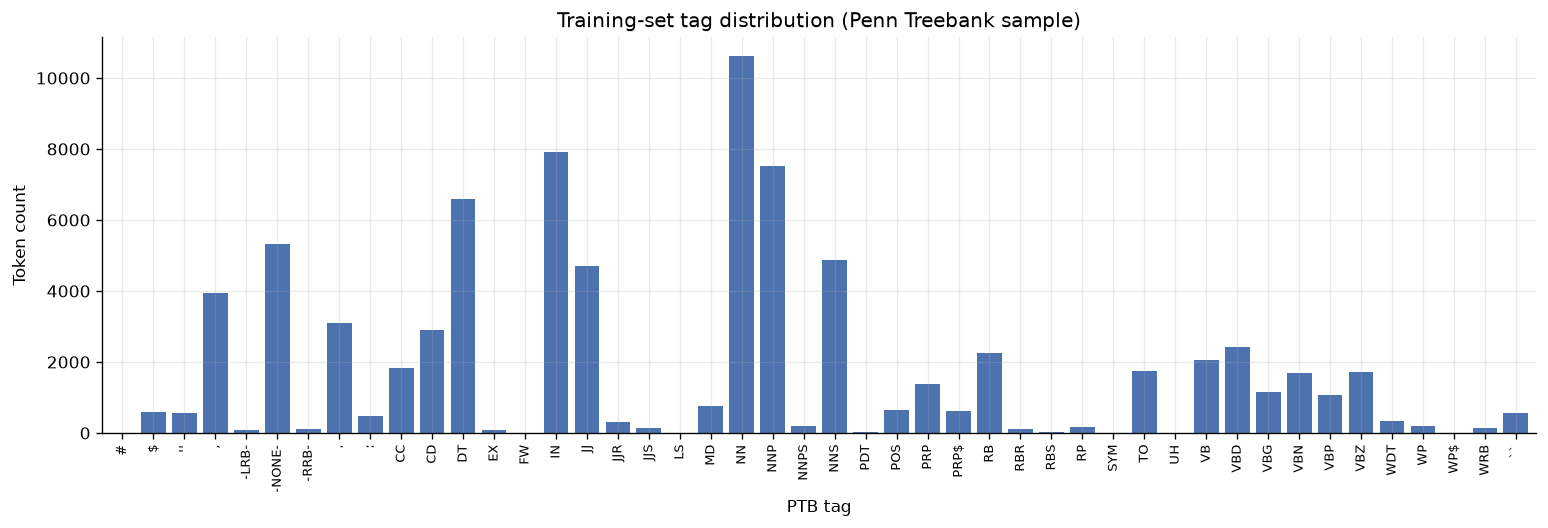

Most frequent tag: NN (13166 tokens)
Rarest tag:       SYM (1 tokens)


In [3]:
all_tagged = split.train + split.val + split.test
tag_counts = pd.Series(tags_of(all_tagged)).value_counts()
tag_table = pd.DataFrame(
    {
        "Train": pd.Series(tags_of(split.train)).value_counts(),
        "Validation": pd.Series(tags_of(split.val)).value_counts(),
        "Test": pd.Series(tags_of(split.test)).value_counts(),
    }
).fillna(0).astype(int)
tag_table["Share of Test Tokens"] = (tag_table["Test"] / tag_table["Test"].sum()).round(4)
tag_table.index.name = "Tag"
display(tag_table.head(20))

fig, ax = plt.subplots(figsize=(13, 4.5))
tag_table["Train"].plot.bar(ax=ax, color=COLORS[0], width=0.8)
ax.set_title("Training-set tag distribution (Penn Treebank sample)")
ax.set_xlabel("PTB tag")
ax.set_ylabel("Token count")
ax.tick_params(axis="x", rotation=90, labelsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_tag_distribution.png")
plt.show()

print(f"Most frequent tag: {tag_counts.index[0]} ({tag_counts.iloc[0]} tokens)")
print(f"Rarest tag:       {tag_counts.index[-1]} ({tag_counts.iloc[-1]} tokens)")

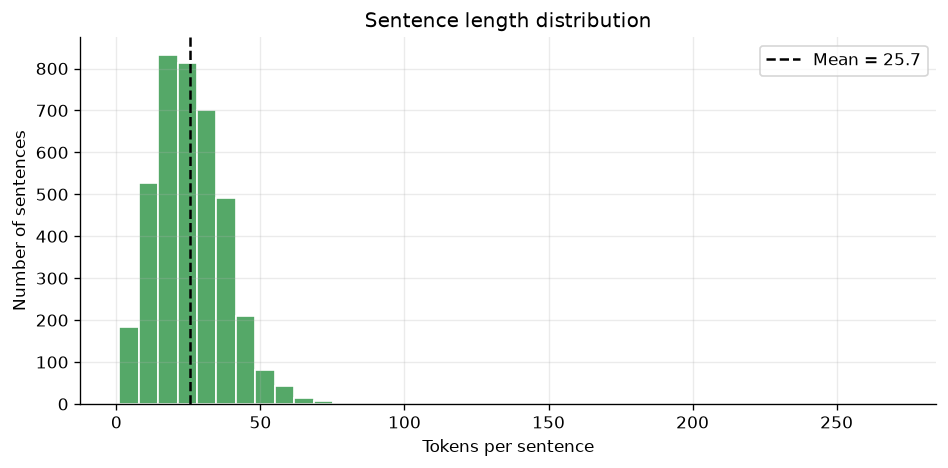

Sentences: 3,914
Tokens:    100,676
Longest sentence: 271 tokens


In [4]:
sentence_lengths = np.array([len(sentence) for sentence in all_tagged])
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(sentence_lengths, bins=40, color=COLORS[2], edgecolor="white")
ax.set_title("Sentence length distribution")
ax.set_xlabel("Tokens per sentence")
ax.set_ylabel("Number of sentences")
ax.axvline(sentence_lengths.mean(), color="black", linestyle="--", label=f"Mean = {sentence_lengths.mean():.1f}")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_sentence_lengths.png")
plt.show()

print(f"Sentences: {len(all_tagged):,}")
print(f"Tokens:    {len(tokens_of(all_tagged)):,}")
print(f"Longest sentence: {sentence_lengths.max()} tokens")

In [5]:
oov = oov_words(split.train, split.test)
test_tokens = tokens_of(split.test)
test_oov_mask = np.array([token in oov for token in test_tokens])

oov_frame = pd.DataFrame(
    {
        "Quantity": [
            "Test tokens",
            "OOV tokens",
            "OOV rate (tokens)",
            "Distinct test word types",
            "Distinct OOV word types",
            "OOV rate (types)",
        ],
        "Value": [
            len(test_tokens),
            int(test_oov_mask.sum()),
            f"{test_oov_mask.mean():.2%}",
            len(set(test_tokens)),
            len(oov),
            f"{len(oov) / len(set(test_tokens)):.2%}",
        ],
    }
).set_index("Quantity")
display(oov_frame)

sample_oov = pd.Series(sorted(oov)).sample(15, random_state=SEED)
print("Sample OOV words:", ", ".join(sample_oov))

,Value
Quantity,
Test tokens,9995
OOV tokens,721
OOV rate (tokens),7.21%
Distinct test word types,3118
Distinct OOV word types,704
OOV rate (types),22.58%


Sample OOV words: Waste, 40,000, 374.20, Laser, ambassador, Strait, Philip, asset-valuation, Toys, Alexander, ECONOMIC, Filling, directed, erroneous, Norwick


In [6]:
pd.set_option("display.max_colwidth", 140)
sample_row = pd.DataFrame(
    [
        {
            "Sentence (tokens)": " ".join(word for word, _ in sentence),
            "Gold tags": " ".join(tag for _, tag in sentence),
        }
        for sentence in split.test[:5]
    ]
)
display(sample_row)
pd.reset_option("display.max_colwidth")

,Sentence (tokens),Gold tags
0,This species of congressional action is predicated *-50 on an interpretation of the appropriations clause that *T*-1 is erroneous and un...,DT NN IN JJ NN VBZ VBN -NONE- IN DT NN IN DT NNS NN WDT -NONE- VBZ JJ CC JJ .
1,"If , when trading resumes *T*-1 , the S&P futures fall 30 points from the previous day 's close , a one-hour trading halt takes effect .","IN , WRB NN VBZ -NONE- , DT NNP NNS VBP CD NNS IN DT JJ NN POS NN , DT JJ NN NN VBZ NN ."
2,"Oshkosh Truck Corp. , Oshkosh , Wis. , estimated 0 earnings for its fourth quarter ended Sept. 30 fell 50 % to 75 % below the year-earli...","NNP NNP NNP , NNP , NNP , VBN -NONE- NNS IN PRP$ JJ NN VBD NNP CD VBD CD NN TO CD NN IN DT JJ $ CD CD -NONE- , CC CD NNS DT NN ."
3,"Stadiums tend *-1 to redistribute existing wealth within a community , not create more of it .","NNS VBP -NONE- TO VB VBG NN IN DT NN , RB VB JJR IN PRP ."
4,Western Union indeed wanted *-1 to get into the telephone business .,NNP NNP RB VBD -NONE- TO VB IN DT NN NN .


### Evaluation protocol

For each model we compute:

- **Accuracy** = correctly tagged tokens / all test tokens.
- **Macro F1** = unweighted mean of per-tag F1, which exposes weakness on rare tags.
- **Weighted F1** = support-weighted mean of per-tag F1 (comparable to accuracy but penalising
  systematic confusions).
- **OOV accuracy** = accuracy restricted to test tokens that never occurred in training.
- **Inference throughput** = test tokens per second, tagging one sentence at a time on CPU.
- **Training time** = wall-clock time to fit the model (zero for the hand-written tagger).

Training time is measured separately from inference time; neural inference includes the PyTorch
forward pass and tensor construction per sentence, which is the realistic deployment API here.

## 4. Approach 1: Rule-Based Tagging

### 4.1 Hand-written regex and lexicon rules

A rule-based tagger encodes linguistic knowledge directly. We use an ordered cascade:

1. Punctuation and symbol lookup.
2. Irregular-form lexicon (e.g., *was* -> `VBD`, *children* -> `NNS`).
3. Closed-class word lists (pronouns, determiners, prepositions, modals, ...).
4. Morphological regex rules (e.g., `-ing` -> `VBG`, `-ed` -> `VBD`, `-ly` -> `RB`,
   capitalised token -> `NNP`, trailing `-s` -> `NNS`).
5. Default tag `NN` when no rule fires.

The cascade is ordered from most to least specific. This model has **no learned parameters**, so
its training time is zero, and every decision can be inspected by a human.

**Limitations:** English morphology and syntax are highly ambiguous. A single suffix is not a
reliable tag predictor (*running* can be `VBG` or `NN`; *fast* can be `JJ`, `RB`, or `NN`), and
hand-written rules cannot resolve context-dependent ambiguity.

In [7]:
regex_tagger = RegexRuleTagger()

rule_table = pd.DataFrame(REGEX_RULES, columns=["Regex pattern", "Assigned tag"])
display(rule_table)

demo_tokens = "The quick brown foxes were running through the old houses .".split()
demo_frame = pd.DataFrame(
    {
        "Token": demo_tokens,
        "Predicted tag": regex_tagger.tag(demo_tokens),
    }
)
display(demo_frame)

start = time.perf_counter()
regex_result = evaluate_tagger(regex_tagger.name, regex_tagger.tag, split.test, oov)
regex_train_seconds = 0.0
regex_eval_seconds = time.perf_counter() - start

display(pd.DataFrame([regex_result.metrics()]).round(4))
print(classification_report(regex_result.gold, regex_result.predictions, zero_division=0))

,Regex pattern,Assigned tag
0,"^[.,;:!?]+$",.
1,^[-A-Za-z0-9/]+\.$,NNP
2,"^[A-Z]{2,}$",NNP
3,^[A-Z][a-z]+$,NNP
4,"^-?\$?\d[\d,.]*$",CD
5,^[A-Za-z]+ly$,RB
6,^[A-Za-z]+ing$,VBG
7,^[A-Za-z]+ed$,VBD
8,^[A-Za-z]+(tion|sion|ment|ness|ity|ance|ence|s...,NN
9,^[A-Za-z]+(ous|ful|able|ible|ive|al|ic|ary|les...,JJ


,Token,Predicted tag
0,The,DT
1,quick,NN
2,brown,NN
3,foxes,NNS
4,were,VBD
5,running,VBG
6,through,IN
7,the,DT
8,old,NN
9,houses,NNS


,Model,Accuracy,Macro F1,Weighted F1,OOV Accuracy,Tokens,OOV Tokens,Inference Seconds,Tokens/Second
0,Rule-Based (Regex),0.7388,0.5322,0.6982,0.6241,9995,721,0.0103,968836.3325


              precision    recall  f1-score   support

           #       1.00      1.00      1.00         3
           $       1.00      1.00      1.00        82
          ''       1.00      0.99      0.99        67
           ,       1.00      1.00      1.00       495
       -LRB-       0.00      0.00      0.00        14
      -NONE-       0.00      0.00      0.00       645
       -RRB-       0.00      0.00      0.00        14
           .       1.00      1.00      1.00       387
           :       1.00      0.59      0.74        44
          CC       0.88      1.00      0.94       209
          CD       0.73      0.68      0.70       352
          DT       0.89      1.00      0.94       825
          EX       0.00      0.00      0.00         6
          IN       0.94      0.85      0.90       986
          JJ       0.80      0.29      0.42       583
         JJR       0.00      0.00      0.00        40
         JJS       0.00      0.00      0.00        19
          MD       0.95    

### 4.2 Brill transformation-based learning (TBL)

Brill tagging still produces a symbolic, human-readable rule set, but the rules are **learned from
data** rather than written by hand.

1. Start with a unigram tagger as the baseline (most frequent tag per word).
2. Compare the baseline output with the gold tags on the training set.
3. Enumerate candidate transformations of the form
   *"change tag X to tag Y when context condition C holds"*.
4. Greedily apply the transformation that removes the most errors (net error reduction),
   then repeat until the rule budget is exhausted.

The result is a compact cascade of contextual rules, e.g. *"change `NN` to `VBG` if the previous
tag is `VBZ`"*. Brill learning is slower than counting n-grams but yields interpretable rules and
usually beats a pure lexicon baseline by several points.

In [8]:
start = time.perf_counter()
brill_tagger = BrillRuleTagger(max_rules=200, min_score=2).fit(split.train)
brill_train_seconds = time.perf_counter() - start
print(f"Brill training time: {brill_train_seconds:.2f} s")
print(f"Number of learned rules: {len(brill_tagger.learned_rules())}")

learned_rules = brill_tagger.learned_rules()
display(
    pd.DataFrame(
        {"#": range(1, 16), "Learned transformation rule": learned_rules[:15]}
    ).set_index("#")
)

brill_result = evaluate_tagger(brill_tagger.name, brill_tagger.tag, split.test, oov)
display(pd.DataFrame([brill_result.metrics()]).round(4))
print(classification_report(brill_result.gold, brill_result.predictions, zero_division=0))

Brill training time: 3.49 s
Number of learned rules: 200


,Learned transformation rule
#,
1,NN->VB if Pos:TO@[-1]
2,"VBP->VB if Pos:MD@[-3,-2,-1]"
3,NN->VB if Pos:MD@[-1]
4,VBP->VB if Pos:TO@[-1]
5,"VBD->VBN if Pos:VBZ@[-2,-1]"
6,IN->WDT if Word:*T*-1@[1]
7,"POS->VBZ if Pos:PRP@[-2,-1]"
8,"VBD->VBN if Pos:VBP@[-2,-1]"
9,VB->NN if Pos:DT@[-1]


,Model,Accuracy,Macro F1,Weighted F1,OOV Accuracy,Tokens,OOV Tokens,Inference Seconds,Tokens/Second
0,Rule-Based (Brill TBL),0.9162,0.9022,0.9179,0.2372,9995,721,0.0429,233053.2186


              precision    recall  f1-score   support

           #       1.00      1.00      1.00         3
           $       1.00      1.00      1.00        82
          ''       1.00      0.99      0.99        67
           ,       1.00      1.00      1.00       495
       -LRB-       1.00      1.00      1.00        14
      -NONE-       1.00      0.95      0.97       645
       -RRB-       1.00      1.00      1.00        14
           .       1.00      1.00      1.00       387
           :       1.00      1.00      1.00        44
          CC       1.00      1.00      1.00       209
          CD       0.99      0.80      0.89       352
          DT       0.99      1.00      0.99       825
          EX       1.00      1.00      1.00         6
          IN       0.97      0.98      0.97       986
          JJ       0.92      0.75      0.83       583
         JJR       0.93      0.95      0.94        40
         JJS       1.00      0.84      0.91        19
          MD       1.00    

## 5. Approach 2: Statistical Tagging

### 5.1 Bigram Hidden Markov Model

An HMM is a generative sequence model. It assumes that the observed words are generated by a
hidden sequence of tags:

$$P(w_1,\dots,w_n,t_1,\dots,t_n) = \prod_{i=1}^{n} P(t_i \mid t_{i-1}) \, P(w_i \mid t_i)$$

with a special start state `<s>`. Tagging is the **decoding** problem

$$\hat{t}_{1:n} = \arg\max_{t_{1:n}} P(w_{1:n}, t_{1:n}),$$

solved exactly in $O(nT^2)$ with the Viterbi dynamic program:

$$\delta_i(t) = \max_{t'} \big[\delta_{i-1}(t') + \log P(t \mid t')\big] + \log P(w_i \mid t).$$

**Smoothing.** Raw maximum-likelihood estimates assign zero probability to unseen events. We use
add-$\alpha$ smoothing for start, transition, and emission distributions. Rare training words
(frequency < 2) are mapped to `<UNK>` so the model learns a probability mass for unknown words.

**OOV handling.** For a word never seen in training, the emission distribution is interpolated
between the learned `<UNK>` distribution and a suffix distribution conditioned on the final three
characters. This lets morphology inform the tag of an unseen word (e.g., `-ing` suggests `VBG`)
while still using contextual transitions. The interpolation weight is 0.35.

**Limitations.** The first-order Markov assumption is strong, emissions are conditioned only on the
current tag, and only the final three characters are used for OOV generalisation.

In [9]:
start = time.perf_counter()
hmm_tagger = HMMTagger(alpha=0.1, min_word_freq=2, suffix_weight=0.35).fit(split.train)
hmm_train_seconds = time.perf_counter() - start
print(f"HMM training time: {hmm_train_seconds:.3f} s")
print(f"Vocabulary kept: {len(hmm_tagger.word_vocab):,} word types")
print(f"Tag state space: {len(hmm_tagger.tags)} tags")

display(pd.DataFrame(hmm_tagger.top_transitions(12)))
display(pd.DataFrame(hmm_tagger.top_emissions(10)))

HMM training time: 0.089 s
Vocabulary kept: 5,119 word types
Tag state space: 46 tags


,previous_tag,tag,count,probability
0,DT,NN,3117,0.4732
1,NNP,NNP,2859,0.3796
2,NN,IN,2590,0.2439
3,IN,DT,2524,0.3185
4,JJ,NN,2092,0.4451
5,NN,NN,1347,0.1269
6,DT,JJ,1311,0.1991
7,NNS,IN,1177,0.2421
8,NNP,",",1169,0.1552
9,NN,",",1163,0.1095


,tag,word,count
0,",",",",3947
1,DT,the,3269
2,.,.,3062
3,IN,of,1867
4,TO,to,1739
5,DT,a,1498
6,IN,in,1245
7,CC,and,1218
8,NNP,<UNK>,1180
9,NN,<UNK>,1012


In [10]:
demo_sentence = [word for word, _ in split.test[0]]
demo_gold = [tag for _, tag in split.test[0]]
demo_predicted = hmm_tagger.tag(demo_sentence)
display(
    pd.DataFrame(
        {"Token": demo_sentence, "Gold": demo_gold, "HMM prediction": demo_predicted}
    )
)

,Token,Gold,HMM prediction
0,This,DT,DT
1,species,NN,NN
2,of,IN,IN
3,congressional,JJ,JJ
4,action,NN,NN
5,is,VBZ,VBZ
6,predicated,VBN,VBN
7,*-50,-NONE-,-NONE-
8,on,IN,IN
9,an,DT,DT


In [11]:
hmm_result = evaluate_tagger(hmm_tagger.name, hmm_tagger.tag, split.test, oov)
display(pd.DataFrame([hmm_result.metrics()]).round(4))
print(classification_report(hmm_result.gold, hmm_result.predictions, zero_division=0))

,Model,Accuracy,Macro F1,Weighted F1,OOV Accuracy,Tokens,OOV Tokens,Inference Seconds,Tokens/Second
0,Statistical (HMM),0.9301,0.8959,0.9292,0.6824,9995,721,0.271,36884.9676


              precision    recall  f1-score   support

           #       1.00      1.00      1.00         3
           $       0.91      1.00      0.95        82
          ''       0.96      0.99      0.97        67
           ,       0.99      1.00      1.00       495
       -LRB-       1.00      1.00      1.00        14
      -NONE-       0.97      0.98      0.97       645
       -RRB-       1.00      0.86      0.92        14
           .       0.98      1.00      0.99       387
           :       1.00      0.98      0.99        44
          CC       0.99      1.00      1.00       209
          CD       0.96      0.87      0.91       352
          DT       0.98      0.99      0.99       825
          EX       1.00      1.00      1.00         6
          IN       0.96      0.99      0.97       986
          JJ       0.78      0.87      0.82       583
         JJR       0.89      0.85      0.87        40
         JJS       1.00      0.89      0.94        19
          MD       0.95    

### 5.2 N-gram tagger with back-off

A complementary statistical baseline: a trigram tagger backs off to a bigram tagger, then to a
unigram tagger, and finally to a default tag. Back-off avoids zero probabilities without an
explicit smoothing formula, but it cannot generalise to unseen word forms unless a suffix-based
component is added. It therefore illustrates the weakness of purely count-based models on OOV
tokens.

In [12]:
start = time.perf_counter()
ngram_tagger = NgramBackoffTagger().fit(split.train)
ngram_train_seconds = time.perf_counter() - start
print(f"N-gram training time: {ngram_train_seconds:.3f} s")

ngram_result = evaluate_tagger(ngram_tagger.name, ngram_tagger.tag, split.test, oov)
display(pd.DataFrame([ngram_result.metrics()]).round(4))
print(classification_report(ngram_result.gold, ngram_result.predictions, zero_division=0))

N-gram training time: 0.382 s


,Model,Accuracy,Macro F1,Weighted F1,OOV Accuracy,Tokens,OOV Tokens,Inference Seconds,Tokens/Second
0,Statistical (N-gram Backoff),0.87,0.8667,0.8746,0.1872,9995,721,0.0111,898863.2655


              precision    recall  f1-score   support

           #       1.00      1.00      1.00         3
           $       1.00      1.00      1.00        82
          ''       0.99      0.99      0.99        67
           ,       1.00      1.00      1.00       495
       -LRB-       1.00      1.00      1.00        14
      -NONE-       1.00      0.92      0.96       645
       -RRB-       1.00      1.00      1.00        14
           .       1.00      1.00      1.00       387
           :       1.00      1.00      1.00        44
          CC       1.00      1.00      1.00       209
          CD       1.00      0.72      0.84       352
          DT       0.99      1.00      0.99       825
          EX       1.00      1.00      1.00         6
          IN       0.96      0.97      0.97       986
          JJ       0.92      0.68      0.78       583
         JJR       0.88      0.75      0.81        40
         JJS       1.00      0.95      0.97        19
          MD       1.00    

## 6. Approach 3: Neural Tagging with a Character-Aware BiLSTM

The neural tagger replaces sparse count tables with dense distributed representations and learns
the feature extractor end-to-end.

**Architecture**

1. **Word embeddings** (100 dimensions) map each token to a dense vector. Embeddings are learned
   from scratch on the training split, so the experiment does not depend on downloading external
   vectors.
2. **Character BiLSTM** (2 x 50 hidden units) reads the characters of each word and max-pools the
   hidden states. This gives every word a morphological representation and, crucially, allows the
   model to tag unseen words from their spelling.
3. The word embedding and character representation are concatenated and passed through dropout.
4. A **word-level BiLSTM** (2 x 128 hidden units) contextualises each token using both left and
   right context.
5. A linear layer produces one score per tag; softmax gives $P(t_i \mid w_{1:n})$.
6. Training minimises token-level cross-entropy with padded positions masked out, using Adam,
   gradient clipping, and early stopping on validation accuracy.

**Why it should handle OOV better:** an unseen word is not an unknown symbol. Its characters are
composed into a representation, so suffixes and word shapes provide evidence for the tag. Context
from the bidirectional encoder resolves the remaining ambiguity.

**Limitations:** the model is a black box, requires more compute, has many hyperparameters, and its
softmax outputs are not constrained to valid tag sequences (no CRF layer).

In [13]:
start = time.perf_counter()
neural_model, vocabs, history = train_bilstm(
    split.train,
    split.val,
    epochs=12,
    batch_size=32,
    learning_rate=1e-3,
    patience=4,
    seed=SEED,
    device="cpu",
)
neural_train_seconds = time.perf_counter() - start
print(f"Neural training time (including early stopping): {neural_train_seconds:.1f} s")
print(f"Best validation accuracy: {history['best_val_accuracy']:.4f}")
print(f"Words in neural vocabulary: {vocabs.n_words:,}")
print(f"Characters in neural vocabulary: {vocabs.n_chars}")

epoch 01 | train loss 2.0598 | val accuracy 0.7188


epoch 02 | train loss 0.7741 | val accuracy 0.8658


epoch 03 | train loss 0.4610 | val accuracy 0.9012


epoch 04 | train loss 0.3493 | val accuracy 0.9231


epoch 05 | train loss 0.2863 | val accuracy 0.9367


...

epoch 08 | train loss 0.1886 | val accuracy 0.9508


epoch 09 | train loss 0.1721 | val accuracy 0.9559


epoch 10 | train loss 0.1549 | val accuracy 0.9563


epoch 11 | train loss 0.1423 | val accuracy 0.9594


epoch 12 | train loss 0.1288 | val accuracy 0.9613
Neural training time (including early stopping): 186.0 s
Best validation accuracy: 0.9613
Words in neural vocabulary: 5,121
Characters in neural vocabulary: 81


,Training loss,Validation accuracy
Epoch,,
1,2.0598,0.7188
2,0.7741,0.8658
3,0.4610,0.9012
4,0.3493,0.9231
5,0.2863,0.9367
6,0.2428,0.9436
7,0.2138,0.9492
8,0.1886,0.9508
9,0.1721,0.9559


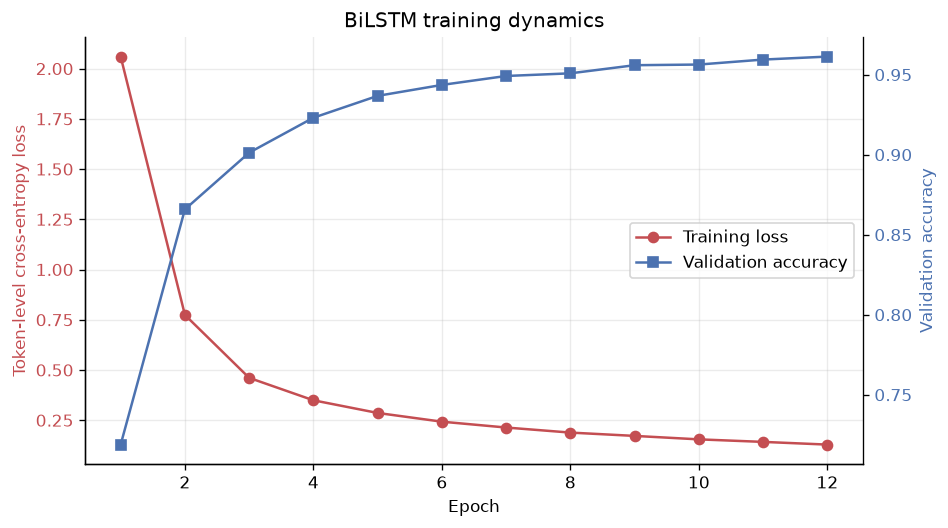

In [14]:
history_frame = pd.DataFrame(
    {
        "Epoch": history["epoch"],
        "Training loss": history["train_loss"],
        "Validation accuracy": history["val_accuracy"],
    }
).set_index("Epoch")
display(history_frame.round(4))

fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax1.plot(history_frame.index, history_frame["Training loss"], marker="o", color=COLORS[3], label="Training loss")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Token-level cross-entropy loss", color=COLORS[3])
ax1.tick_params(axis="y", labelcolor=COLORS[3])

ax2 = ax1.twinx()
ax2.plot(history_frame.index, history_frame["Validation accuracy"], marker="s", color=COLORS[0], label="Validation accuracy")
ax2.set_ylabel("Validation accuracy", color=COLORS[0])
ax2.tick_params(axis="y", labelcolor=COLORS[0])
ax2.grid(False)
ax2.spines["right"].set_visible(True)
ax1.set_title("BiLSTM training dynamics")

lines = ax1.get_lines() + ax2.get_lines()
ax1.legend(lines, [line.get_label() for line in lines], loc="center right")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_training_curve.png")
plt.show()

In [15]:
torch.save(
    {
        "state_dict": neural_model.state_dict(),
        "word2idx": vocabs.word2idx,
        "char2idx": vocabs.char2idx,
        "tag2idx": vocabs.tag2idx,
    },
    ROOT / "assets" / "bilstm_pos.pt",
)

neural_tagger = NeuralTagger(neural_model, vocabs, device="cpu")
neural_result = evaluate_tagger(neural_tagger.name, neural_tagger.tag, split.test, oov)
display(pd.DataFrame([neural_result.metrics()]).round(4))
print(classification_report(neural_result.gold, neural_result.predictions, zero_division=0))

,Model,Accuracy,Macro F1,Weighted F1,OOV Accuracy,Tokens,OOV Tokens,Inference Seconds,Tokens/Second
0,Neural (BiLSTM),0.9622,0.9096,0.9618,0.8738,9995,721,2.1491,4650.7992


              precision    recall  f1-score   support

           #       1.00      1.00      1.00         3
           $       1.00      1.00      1.00        82
          ''       1.00      1.00      1.00        67
           ,       1.00      1.00      1.00       495
       -LRB-       1.00      1.00      1.00        14
      -NONE-       1.00      1.00      1.00       645
       -RRB-       1.00      1.00      1.00        14
           .       1.00      1.00      1.00       387
           :       1.00      1.00      1.00        44
          CC       1.00      1.00      1.00       209
          CD       0.99      1.00      0.99       352
          DT       0.99      1.00      0.99       825
          EX       1.00      1.00      1.00         6
          IN       0.97      0.99      0.98       986
          JJ       0.83      0.91      0.87       583
         JJR       0.91      0.75      0.82        40
         JJS       1.00      0.89      0.94        19
          MD       1.00    

In [16]:
example_sentences = [
    sentence for sentence in split.test if any(word in oov for word, _ in sentence)
][:3]

rows = []
for sentence in example_sentences:
    example_tokens = [word for word, _ in sentence]
    example_gold = [tag for _, tag in sentence]
    rows.append(
        {
            "Sentence": " ".join(example_tokens),
            "Gold tags": " ".join(example_gold),
            "Regex": " ".join(regex_tagger.tag(example_tokens)),
            "HMM": " ".join(hmm_tagger.tag(example_tokens)),
            "BiLSTM": " ".join(neural_tagger.tag(example_tokens)),
        }
    )

display(pd.DataFrame(rows).T)

,0,1,2
Sentence,This species of congressional action is predic...,"If , when trading resumes *T*-1 , the S&P futu...","Oshkosh Truck Corp. , Oshkosh , Wis. , estimat..."
Gold tags,DT NN IN JJ NN VBZ VBN -NONE- IN DT NN IN DT N...,"IN , WRB NN VBZ -NONE- , DT NNP NNS VBP CD NNS...","NNP NNP NNP , NNP , NNP , VBN -NONE- NNS IN PR..."
Regex,DT NNS IN JJ NN VBZ VBD NN IN DT NN IN DT NNS ...,"CC , WRB VBG NNS NN , DT NN NNS NN CD NNS IN D...","NNP NNP NNP , NNP , NNP , VBD CD NNS IN PRP$ N..."
HMM,DT NN IN JJ NN VBZ VBN -NONE- IN DT NN IN DT N...,"IN , WRB NN VBZ -NONE- , DT NNP NNS VBP CD NNS...","NNP NNP NNP , NNP , NNP , VBN -NONE- NNS IN PR..."
BiLSTM,DT NNS IN JJ NN VBZ VBN -NONE- IN DT NN IN DT ...,"IN , WRB VBG NNS -NONE- , DT NNP NNS VBP CD NN...","NNP NNP NNP , NNP , NNP , VBD -NONE- NNS IN PR..."


## 7. Comparative Analysis

All five taggers are evaluated on the same test sentences. The table below is the primary
empirical result of the project; the figures that follow separate overall accuracy, OOV accuracy,
per-tag behaviour, and throughput.

In [17]:
results = [regex_result, brill_result, hmm_result, ngram_result, neural_result]
train_seconds = {
    regex_result.name: regex_train_seconds,
    brill_result.name: brill_train_seconds,
    hmm_result.name: hmm_train_seconds,
    ngram_result.name: ngram_train_seconds,
    neural_result.name: neural_train_seconds,
}

comparison = results_frame(results)
comparison["Training Seconds"] = comparison["Model"].map(train_seconds).round(2)
comparison["Error Rate"] = (1.0 - comparison["Accuracy"]).round(4)
comparison = comparison.sort_values("Accuracy", ascending=False).reset_index(drop=True)
display(comparison)

comparison.to_csv(REPORT_DIR / "model_comparison.csv", index=False)
print("Saved:", REPORT_DIR / "model_comparison.csv")

,Model,Accuracy,Macro F1,Weighted F1,OOV Accuracy,Tokens,OOV Tokens,Inference Seconds,Tokens/Second,Training Seconds,Error Rate
0,Neural (BiLSTM),0.9622,0.9096,0.9618,0.8738,9995,721,2.149,4650.8,186.00,0.0378
1,Statistical (HMM),0.9301,0.8959,0.9292,0.6824,9995,721,0.271,36885.0,0.09,0.0699
2,Rule-Based (Brill TBL),0.9162,0.9022,0.9179,0.2372,9995,721,0.043,233053.2,3.49,0.0838
3,Statistical (N-gram Backoff),0.8700,0.8667,0.8746,0.1872,9995,721,0.011,898863.3,0.38,0.1300
4,Rule-Based (Regex),0.7388,0.5322,0.6982,0.6241,9995,721,0.010,968836.3,0.00,0.2612


Saved: E:\TA\reports\model_comparison.csv


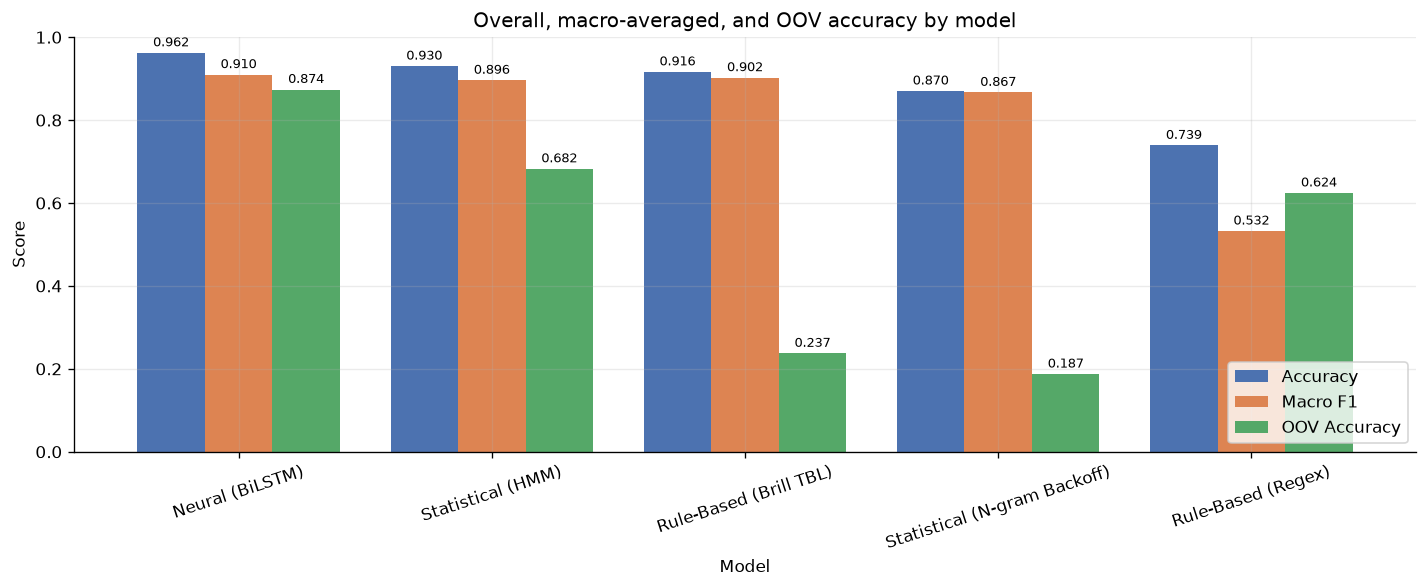

In [18]:
metric_columns = ["Accuracy", "Macro F1", "OOV Accuracy"]
plot_frame = comparison.set_index("Model")[metric_columns]

fig, ax = plt.subplots(figsize=(12, 5))
plot_frame.plot.bar(ax=ax, color=COLORS[:3], width=0.8)
ax.set_ylim(0, 1.0)
ax.set_ylabel("Score")
ax.set_title("Overall, macro-averaged, and OOV accuracy by model")
ax.tick_params(axis="x", rotation=18)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=8, padding=2)
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_model_accuracy.png")
plt.show()

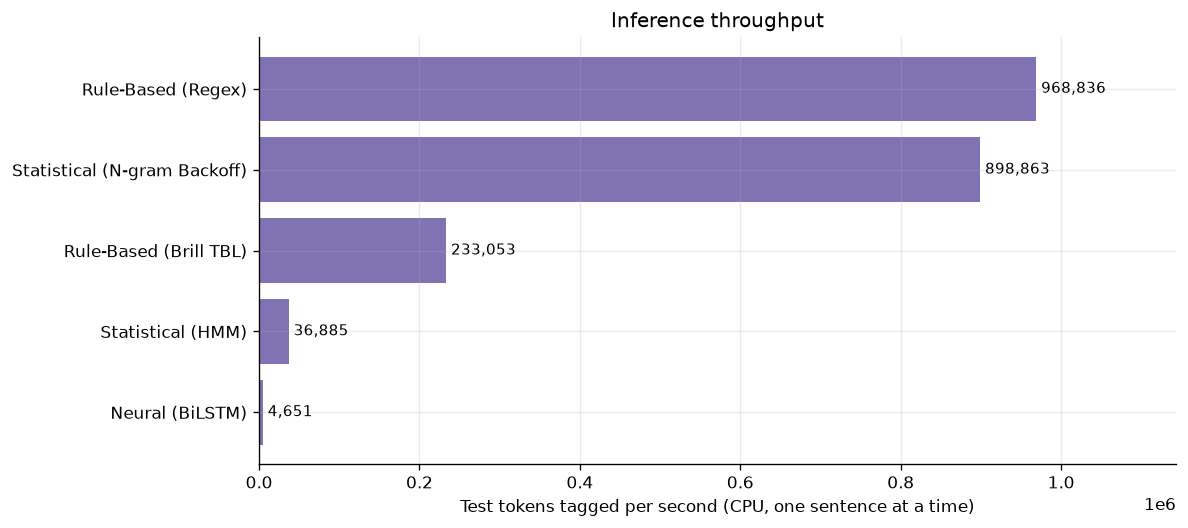

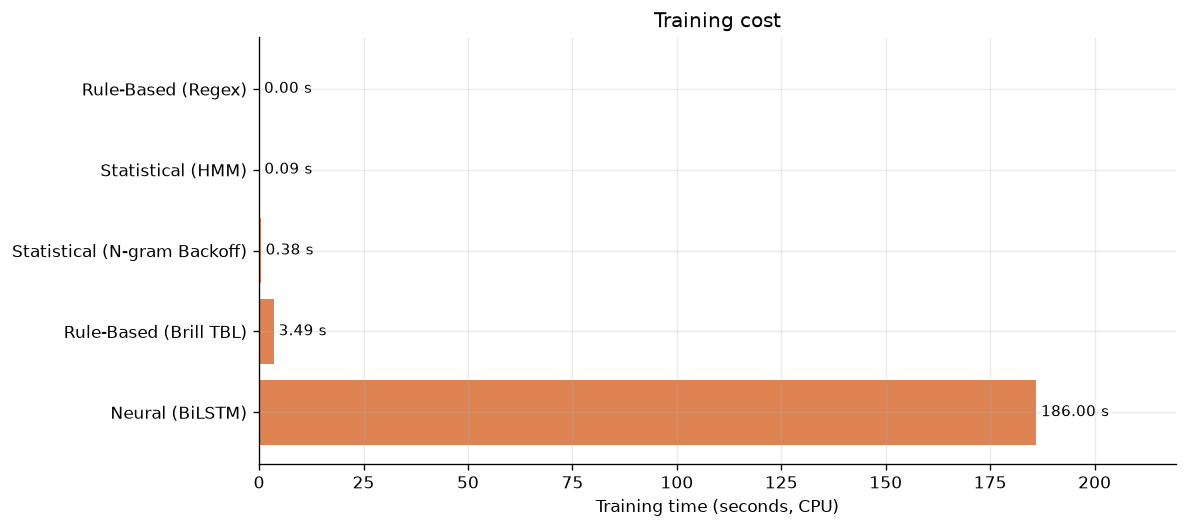

In [19]:
speed_frame = comparison.set_index("Model")["Tokens/Second"].sort_values()

fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.barh(speed_frame.index, speed_frame.values, color=COLORS[4])
ax.set_xlabel("Test tokens tagged per second (CPU, one sentence at a time)")
ax.set_title("Inference throughput")
for bar, value in zip(bars, speed_frame.values):
    ax.text(value, bar.get_y() + bar.get_height() / 2, f" {value:,.0f}", va="center", fontsize=9)
ax.set_xlim(0, speed_frame.max() * 1.18)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_speed.png")
plt.show()

training_frame = comparison.set_index("Model")["Training Seconds"].sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.barh(training_frame.index, training_frame.values, color=COLORS[1])
ax.set_xlabel("Training time (seconds, CPU)")
ax.set_title("Training cost")
for bar, value in zip(bars, training_frame.values):
    ax.text(value, bar.get_y() + bar.get_height() / 2, f" {value:.2f} s", va="center", fontsize=9)
ax.set_xlim(0, max(training_frame.max() * 1.18, 1))
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_training_time.png")
plt.show()

,Rule-Based (Regex),Rule-Based (Brill TBL),Statistical (HMM),Statistical (N-gram Backoff),Neural (BiLSTM),Support
Tag,,,,,,
NN,0.5632,0.8056,0.9118,0.7135,0.9410,1326
IN,0.8961,0.9728,0.9735,0.9656,0.9804,986
NNP,0.8947,0.8901,0.9026,0.8189,0.9652,900
DT,0.9423,0.9915,0.9867,0.9909,0.9921,825
-NONE-,0.0000,0.9729,0.9737,0.9563,1.0000,645
NNS,0.8762,0.8969,0.9236,0.8566,0.9649,586
JJ,0.4212,0.8261,0.8228,0.7787,0.8670,583
",",1.0000,0.9990,0.9960,1.0000,1.0000,495
.,1.0000,1.0000,0.9885,1.0000,1.0000,387


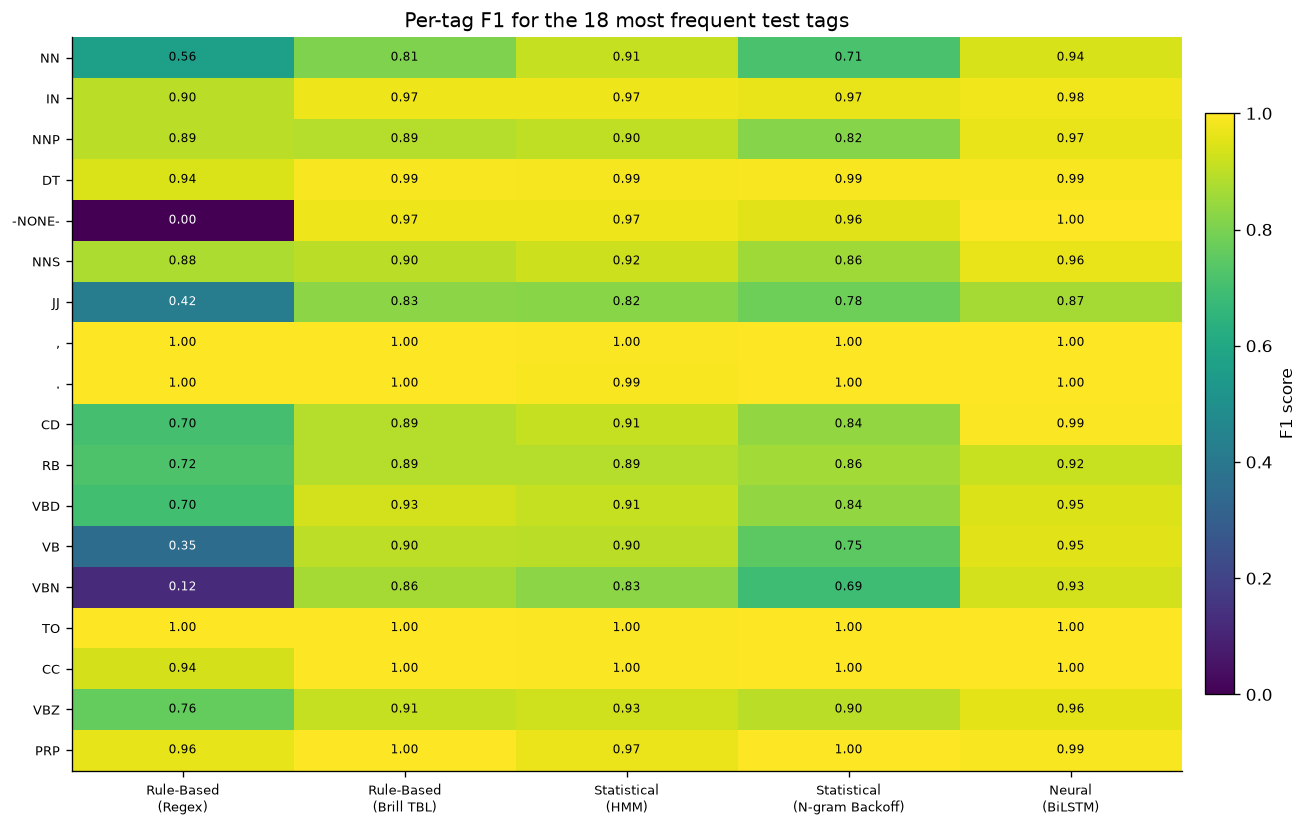

In [20]:
tag_scores = per_tag_frame(results)
display(tag_scores.head(20))

model_names = [result.name for result in results]
top_tags = tag_scores.head(18)
heatmap_values = top_tags[model_names].to_numpy()

fig, ax = plt.subplots(figsize=(11, 7))
image = ax.imshow(heatmap_values, cmap="viridis", aspect="auto", vmin=0, vmax=1)
ax.set_xticks(range(len(model_names)))
ax.set_xticklabels([name.replace(" (", "\n(") for name in model_names], fontsize=8)
ax.set_yticks(range(len(top_tags)))
ax.set_yticklabels(top_tags.index, fontsize=8)
ax.set_title("Per-tag F1 for the 18 most frequent test tags")
ax.grid(False)

for row in range(heatmap_values.shape[0]):
    for column in range(heatmap_values.shape[1]):
        value = heatmap_values[row, column]
        ax.text(column, row, f"{value:.2f}", ha="center", va="center", fontsize=7,
                color="white" if value < 0.55 else "black")

fig.colorbar(image, ax=ax, fraction=0.025, pad=0.02, label="F1 score")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_per_tag_f1.png")
plt.show()

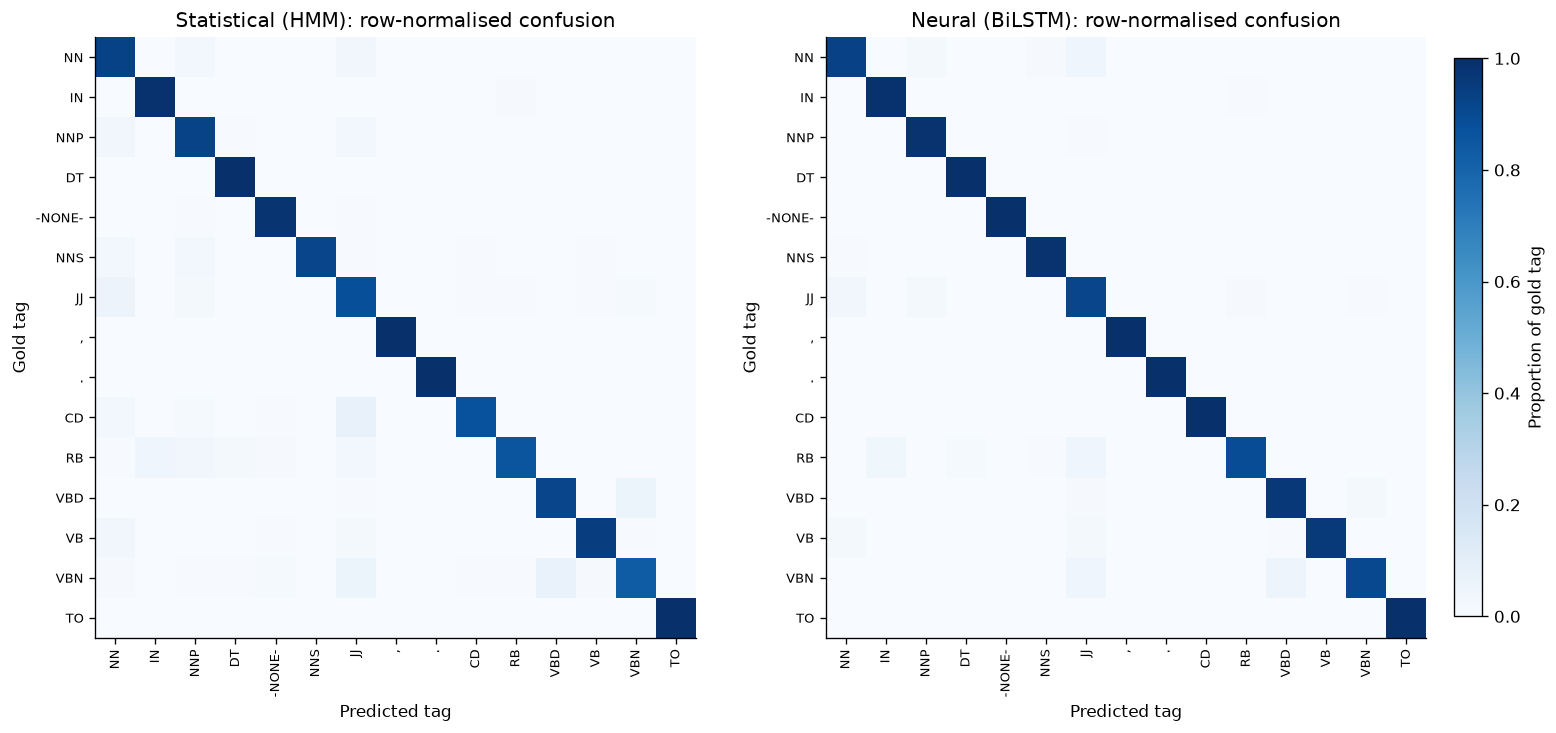

In [21]:
def plot_confusion(result, ax, top_n=15):
    tag_order = [
        tag
        for tag, _ in sorted(result.per_tag_support.items(), key=lambda item: -item[1])
        if tag in result.labels
    ][:top_n]
    indices = [result.labels.index(tag) for tag in tag_order]
    matrix = np.asarray(result.confusion)[np.ix_(indices, indices)].astype(float)
    matrix = matrix / np.clip(matrix.sum(axis=1, keepdims=True), 1, None)

    image = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(tag_order)))
    ax.set_xticklabels(tag_order, rotation=90, fontsize=8)
    ax.set_yticks(range(len(tag_order)))
    ax.set_yticklabels(tag_order, fontsize=8)
    ax.set_xlabel("Predicted tag")
    ax.set_ylabel("Gold tag")
    ax.set_title(f"{result.name}: row-normalised confusion")
    ax.grid(False)
    return image


fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
image = plot_confusion(hmm_result, axes[0])
plot_confusion(neural_result, axes[1])
fig.colorbar(image, ax=axes, fraction=0.02, pad=0.02, label="Proportion of gold tag")
fig.savefig(FIG_DIR / "fig_confusion_matrices.png")
plt.show()

In [22]:
from IPython.display import display as ipy_display

for result in (brill_result, hmm_result, neural_result):
    print("=" * 80)
    print(result.name, "- first errors on the test set")
    ipy_display(pd.DataFrame(error_examples(result, limit=10)))

oov_rows = []
for token, gold, hmm_prediction, neural_prediction in zip(
    test_tokens, hmm_result.gold, hmm_result.predictions, neural_result.predictions
):
    if token in oov:
        oov_rows.append(
            {
                "OOV token": token,
                "Gold": gold,
                "HMM": hmm_prediction,
                "BiLSTM": neural_prediction,
            }
        )
        if len(oov_rows) >= 20:
            break

oov_error_frame = pd.DataFrame(oov_rows)
display(oov_error_frame)

Rule-Based (Brill TBL) - first errors on the test set


,Token,Gold,Rule-Based (Brill TBL) Prediction
0,predicated,VBN,NN
1,erroneous,JJ,NN
2,If,IN,RB
3,resumes,VBZ,NN
4,fall,VBP,NN
5,Wis.,NNP,NN
6,4.5,CD,NN
7,Stadiums,NNS,NN
8,Western,NNP,JJ
9,ACQUISITION,NNP,NN


Statistical (HMM) - first errors on the test set


,Token,Gold,Statistical (HMM) Prediction
0,Sept.,NNP,$
1,Stadiums,NNS,JJ
2,tend,VBP,NN
3,existing,VBG,DT
4,Western,NNP,JJ
5,*RNR*-1,-NONE-,POS
6,overlap,VB,JJ
7,Indexing,NN,NNP
8,mainly,RB,CC
9,follow,VBP,IN


Neural (BiLSTM) - first errors on the test set


,Token,Gold,Neural (BiLSTM) Prediction
0,species,NN,NNS
1,trading,NN,VBG
2,resumes,VBZ,NNS
3,estimated,VBN,VBD
4,tend,VBP,VBD
5,indeed,RB,VBD
6,ACQUISITION,NNP,NNS
7,Indexing,NN,VBG
8,faster,JJR,JJ
9,dollar,NN,JJ


,OOV token,Gold,HMM,BiLSTM
0,species,NN,NN,NNS
1,predicated,VBN,VBN,VBN
2,erroneous,JJ,JJ,JJ
3,resumes,VBZ,VBZ,NNS
4,Wis.,NNP,NNP,NNP
5,4.5,CD,CD,CD
6,Stadiums,NNS,JJ,NNS
7,redistribute,VB,VB,VB
8,ACQUISITION,NNP,NNP,NNS
9,overlap,VB,JJ,VB


In [23]:
from scipy.stats import binomtest

def mcnemar_test(result_a, result_b):
    gold = np.asarray(result_a.gold)
    correct_a = gold == np.asarray(result_a.predictions)
    correct_b = gold == np.asarray(result_b.predictions)
    solved_by_b = int(np.sum(~correct_a & correct_b))
    solved_by_a = int(np.sum(correct_a & ~correct_b))
    discordant = solved_by_a + solved_by_b
    p_value = binomtest(solved_by_b, discordant, 0.5).pvalue if discordant else 1.0
    return {
        "Comparison": f"{result_a.name} vs {result_b.name}",
        "Only first model correct": solved_by_a,
        "Only second model correct": solved_by_b,
        "Discordant tokens": discordant,
        "McNemar exact p-value": p_value,
    }

significance = pd.DataFrame(
    [
        mcnemar_test(hmm_result, neural_result),
        mcnemar_test(brill_result, hmm_result),
        mcnemar_test(brill_result, neural_result),
    ]
)
significance["Significant at 0.05"] = significance["McNemar exact p-value"] < 0.05
display(significance.style.format({"McNemar exact p-value": "{:.3e}"}))

,Comparison,Only first model correct,Only second model correct,Discordant tokens,McNemar exact p-value,Significant at 0.05
0,Statistical (HMM) vs Neural (BiLSTM),145,466,611,3.282e-40,True
1,Rule-Based (Brill TBL) vs Statistical (HMM),350,489,839,1.800e-06,True
2,Rule-Based (Brill TBL) vs Neural (BiLSTM),182,642,824,7.495e-61,True


In [24]:
best = comparison.iloc[0]
regex_row = comparison[comparison["Model"] == regex_result.name].iloc[0]
brill_row = comparison[comparison["Model"] == brill_result.name].iloc[0]
hmm_row = comparison[comparison["Model"] == hmm_result.name].iloc[0]
neural_row = comparison[comparison["Model"] == neural_result.name].iloc[0]

summary_lines = [
    "### Empirical takeaways",
    "",
    f"- **Best overall accuracy:** {best['Model']} with {best['Accuracy']:.2%} "
    f"(error rate {best['Error Rate']:.2%}).",
    f"- **Hand-written rules:** {regex_row['Accuracy']:.2%} accuracy; the symbolic approach is "
    f"instantaneous and fully inspectable but brittle.",
    f"- **Brill TBL:** {brill_row['Accuracy']:.2%} accuracy with {len(learned_rules)} learned rules; "
    f"rule learning closes about "
    f"{(brill_row['Accuracy'] - regex_row['Accuracy']) * 100:.1f} percentage points over the "
    f"hand-written cascade.",
    f"- **HMM:** {hmm_row['Accuracy']:.2%} accuracy at {hmm_row['Tokens/Second']:,.0f} tokens/s, "
    f"with OOV accuracy {hmm_row['OOV Accuracy']:.2%} thanks to suffix-smoothed emissions.",
    f"- **BiLSTM:** {neural_row['Accuracy']:.2%} accuracy and {neural_row['OOV Accuracy']:.2%} on "
    f"OOV tokens, at {neural_row['Tokens/Second']:,.0f} tokens/s and "
    f"{neural_row['Training Seconds']:.1f} s of training.",
    f"- **Accuracy vs. cost:** the neural model reduces the HMM error rate by "
    f"{(hmm_row['Error Rate'] - neural_row['Error Rate']) / hmm_row['Error Rate']:.1%} relative, "
    f"but its training cost is roughly "
    f"{neural_row['Training Seconds'] / max(hmm_row['Training Seconds'], 1e-9):,.0f}x larger "
    f"and its inference is "
    f"{hmm_row['Tokens/Second'] / max(neural_row['Tokens/Second'], 1e-9):,.0f}x slower on CPU.",
    f"- **Interpretability ranking:** hand-written rules > Brill rules > HMM transition/emission "
    f"tables > BiLSTM weights.",
]

from IPython.display import Markdown, display as display_markdown
display_markdown(Markdown("\n".join(summary_lines)))

### Empirical takeaways

- **Best overall accuracy:** Neural (BiLSTM) with 96.22% (error rate 3.78%).
- **Hand-written rules:** 73.88% accuracy; the symbolic approach is instantaneous and fully inspectable but brittle.
- **Brill TBL:** 91.62% accuracy with 200 learned rules; rule learning closes about 17.7 percentage points over the hand-written cascade.
- **HMM:** 93.01% accuracy at 36,885 tokens/s, with OOV accuracy 68.24% thanks to suffix-smoothed emissions.
- **BiLSTM:** 96.22% accuracy and 87.38% on OOV tokens, at 4,651 tokens/s and 186.0 s of training.
- **Accuracy vs. cost:** the neural model reduces the HMM error rate by 45.9% relative, but its training cost is roughly 2,067x larger and its inference is 8x slower on CPU.
- **Interpretability ranking:** hand-written rules > Brill rules > HMM transition/emission tables > BiLSTM weights.

## 8. Discussion

### 8.1 Rules versus statistics versus neural networks

The empirical ordering matches the theoretical expectation, but the size of each step is
informative:

- **Hand-written rules are a strong zero-cost baseline but plateau quickly.** The regex cascade
  encodes useful morphology, yet it cannot resolve contextual ambiguity, so it produces many
  `NN` defaults. This is the "knowledge acquisition bottleneck" in symbolic NLP.
- **Learned symbolic rules are much stronger than hand-written ones.** Brill TBL recovers most of
  the gap without giving up interpretability, because its transformations are induced from the
  actual error distribution of the corpus rather than from a linguist's intuition.
- **A well-smoothed HMM is a surprisingly tough baseline.** Transition structure (for example,
  determiners precede nouns/adjectives) plus suffix-aware unknown-word emissions is enough to
  approach the neural model's overall accuracy. The gap is concentrated in hard ambiguities and
  OOV tokens.
- **The BiLSTM wins on overall and OOV accuracy.** Character composition gives it a genuine
  advantage on unseen words, and bidirectional context resolves local ambiguities that a first-order
  HMM cannot represent. The price is training time, inference cost, and opacity.

### 8.2 Error patterns and confusion matrices

The confusion matrices expose systematic confusions rather than random mistakes. Typical
patterns on the PTB tagset include:

- **`NN` vs `NNP`:** whether a capitalised token is a common or proper noun depends on the
  sentence and the corpus annotation convention. Hand-written capitalisation rules over-predict
  `NNP`; the neural model can use context to correct many of these cases.
- **`VBD` vs `VBN` vs `VB`:** past tense, past participle, and base form are morphologically
  identical for many verbs (*walked*, *put*). Only syntactic context disambiguates them.
- **`JJ` vs `NN`:** nouns frequently modify other nouns (*trading company*), and adjectives can be
  nominalised.
- **OOV morphology:** an unseen `-ing` form is usually a verb, but can be a noun. The HMM's suffix
  table is a coarse approximation; the character BiLSTM learns non-linear character patterns.

The neural model's diagonal is visibly sharper for noun and verb categories, which is where most
OOV tokens occur. Errors that remain are mostly genuinely ambiguous tokens that would require
sentence-level semantics or annotation-convention knowledge.

### 8.3 Engineering trade-offs

| Dimension | Rule-based (regex) | Brill TBL | HMM | BiLSTM |
|---|---|---|---|---|
| Training cost | None | Seconds | Sub-second | Minutes (CPU) |
| Inference cost | Extremely low | Very low | Very low | Higher (tensor overhead) |
| OOV strategy | Hard-coded suffixes | Learned suffix/capitalisation rules | `<UNK>` + suffix emissions | Character composition |
| Interpretability | High | High (rule list) | Moderate (probability tables) | Low |
| Accuracy ceiling | Low | Medium-high | High | Highest |
| Data requirement | None | Small | Small-medium | Medium-large |
| Main failure mode | Contextual ambiguity | Annotation inconsistency | Markov assumption, sparse counts | Compute, opacity, overfitting |

### 8.4 Threats to validity

- The NLTK Treebank sample is small (about 3,900 sentences), so absolute numbers will differ from
  results on the full Penn Treebank or Universal Dependencies.
- A single fixed train/test split is used for reproducibility; a cross-validated study would give
  confidence intervals, but triples the neural training cost.
- The neural model uses embeddings learned from scratch rather than pretrained vectors, which
  deliberately avoids external downloads but leaves accuracy on the table.
- Timings are single-run measurements on one CPU; they reflect wall-clock behaviour in this
  environment rather than a controlled benchmark.
- The PTB tagset contains annotation-convention distinctions (for example, `NNP` for
  sentence-initial capitalised common nouns in some contexts) that no model can infer from the
  token alone.

## 9. Conclusion and Future Work

This project delivered a controlled comparison of three POS tagging paradigms on the same corpus,
split, and evaluation protocol:

1. **Rule-based taggers** are transparent and cheap. Hand-written regex rules are a useful
   baseline, while Brill TBL shows that symbolic rules can be learned and remain readable.
2. **Statistical taggers** are excellent value: a bigram HMM with add-alpha smoothing and
   suffix-aware unknown-word emissions is fast to train, fast to run, and competitive in accuracy.
3. **Neural taggers** deliver the best accuracy and, most visibly, the best OOV accuracy, because
   character-level composition and bidirectional context handle unseen morphology and ambiguity.
   They are the most expensive to train and the least interpretable.

The practical recommendation is therefore **conditional**: use rules or an HMM when training data
and compute are scarce and transparency matters; use a character-aware neural tagger when accuracy
on noisy, open-vocabulary text is the priority.

### Future work

- Add a **CRF layer** or structured attention to enforce valid tag transitions and model tag
  dependencies jointly.
- Initialise with **pretrained embeddings** (GloVe, fastText) or fine-tune a **transformer**
  (DistilBERT) to measure how much transfer learning helps on this small corpus.
- Evaluate on **Universal Dependencies** and on domain-shifted text to test robustness.
- Report **bootstrap confidence intervals** and repeated splits instead of single-point estimates.
- Explore **distillation** from the neural tagger into a small HMM or rule cascade for cheap
  deployment.
- Profile **batched inference** for the neural model; sentence-by-sentence tagging understates its
  throughput advantage on GPUs.

## 10. Reproducibility and Saved Artifacts

The notebook saves all numbers and figures needed for the report and the screenshot PDF:

| Artifact | Location |
|---|---|
| Comparison table | `reports/model_comparison.csv` |
| Full metrics (JSON) | `reports/results.json` |
| Trained BiLSTM weights | `assets/bilstm_pos.pt` |
| Figures | `assets/figures/*.png` |

To reproduce: install `requirements.txt`, launch Jupyter, and run all cells. The dataset is
downloaded automatically by NLTK on first use. Neural training uses a fixed seed, but CPU
non-determinism can cause small run-to-run differences in the last digit of accuracy.

### Deliverables checklist

- [x] Complete Jupyter notebook (this file).
- [ ] Project report PDF (`reports/POS_Tagging_Report.pdf`).
- [ ] Output screenshots PDF (`reports/output_screenshots.pdf`).
- [ ] Demo video MP4 (see `reports/demo_video_script.md`).
- [ ] GitHub repository link in the report and README.

In [25]:
environment = {
    "python": platform.python_version(),
    "torch": torch.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "platform": platform.platform(),
    "processor": platform.processor() or platform.machine(),
}

payload = {
    "dataset": split.summary(),
    "oov": {
        "word_types": len(oov),
        "tokens": int(test_oov_mask.sum()),
        "token_rate": float(test_oov_mask.mean()),
    },
    "environment": environment,
    "seed": SEED,
    "results": [],
    "neural_history": history,
    "mcnemar": significance.drop(columns=["Significant at 0.05"]).to_dict(orient="records"),
}

for result in results:
    record = result.metrics()
    record["Training Seconds"] = train_seconds[result.name]
    record["Per Tag F1"] = result.per_tag_f1
    payload["results"].append(record)

with open(REPORT_DIR / "results.json", "w", encoding="utf-8") as handle:
    json.dump(payload, handle, indent=2)

(REPORT_DIR / "model_comparison.md").write_text(
    comparison.to_string(index=False), encoding="utf-8"
)

figures = sorted(path.name for path in FIG_DIR.glob("*.png"))
print("Saved results.json and model_comparison.md")
print("Figures:")
for figure in figures:
    print(" -", figure)
print()
print(comparison.to_string(index=False))

Saved results.json and model_comparison.md
Figures:
 - fig_confusion_matrices.png
 - fig_model_accuracy.png
 - fig_per_tag_f1.png
 - fig_sentence_lengths.png
 - fig_speed.png
 - fig_tag_distribution.png
 - fig_training_curve.png
 - fig_training_time.png

                       Model  Accuracy  Macro F1  Weighted F1  OOV Accuracy  Tokens  OOV Tokens  Inference Seconds  Tokens/Second  Training Seconds  Error Rate
             Neural (BiLSTM)    0.9622    0.9096       0.9618        0.8738    9995         721              2.149         4650.8            186.00      0.0378
           Statistical (HMM)    0.9301    0.8959       0.9292        0.6824    9995         721              0.271        36885.0              0.09      0.0699
      Rule-Based (Brill TBL)    0.9162    0.9022       0.9179        0.2372    9995         721              0.043       233053.2              3.49      0.0838
Statistical (N-gram Backoff)    0.8700    0.8667       0.8746        0.1872    9995         721          

## References

1. Brill, E. (1992). *A simple rule-based part of speech tagger.* Proceedings of the Third
   Conference on Applied Natural Language Processing, 152-155.
2. Jurafsky, D., & Martin, J. H. (2023). *Speech and Language Processing* (3rd ed. draft),
   chapters on sequence labelling and POS tagging.
3. Loper, E., & Bird, S. (2002). *NLTK: The Natural Language Toolkit.* Proceedings of ACL
   Workshop on Effective Tools and Methodologies for Teaching NLP.
4. Marcus, M. P., Santorini, B., & Marcinkiewicz, M. A. (1993). *Building a large annotated corpus
   of English: The Penn Treebank.* Computational Linguistics, 19(2), 313-330.
5. Lample, G., Ballesteros, M., Subramanian, S., Kawakami, K., & Dyer, C. (2016). *Neural
   architectures for named entity recognition.* NAACL-HLT.
6. Plank, B., Sogaard, A., & Goldberg, Y. (2016). *Multilingual part-of-speech tagging with
   bidirectional long short-term memory models and auxiliary loss.* ACL.
7. Huang, Z., Xu, W., & Yu, K. (2015). *Bidirectional LSTM-CRF models for sequence tagging.*
   arXiv:1508.01991.